# Reducción de dimensionalidad

Al aumentar el número de variables, el volumen del espacio crece tan rápido que los datos quedan dispersos: es la maldición de la dimensionalidad. En espacios de muchas dimensiones las distancias pierden significado, porque todos los puntos quedan casi a la misma distancia unos de otros, y los métodos basados en distancias, como los vecinos más cercanos o el agrupamiento, funcionan mal. La reducción de dimensionalidad busca representar los datos con menos variables conservando la mayor parte de su información {cite}`james2021,hastie2009`.

La celda siguiente ilustra la maldición: para puntos aleatorios en un hipercubo, calcula la diferencia relativa entre la distancia al vecino más lejano y al más cercano. Cuando la dimensión crece, esa diferencia tiende a cero.

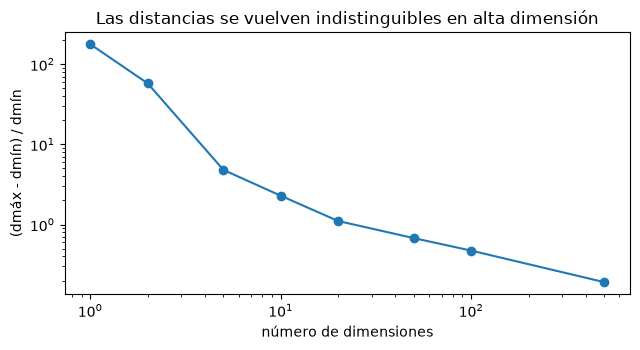

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(8)

dims = [1, 2, 5, 10, 20, 50, 100, 500]
contraste = []
for d in dims:
    P = rng.random((500, d)); q = rng.random((1, d))
    dist = cdist(q, P)[0]
    contraste.append((dist.max() - dist.min()) / dist.min())
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.loglog(dims, contraste, 'o-'); ax.set_xlabel('número de dimensiones'); ax.set_ylabel('(dmáx - dmín) / dmín')
ax.set_title('Las distancias se vuelven indistinguibles en alta dimensión'); plt.tight_layout(); plt.show()

Hay dos enfoques: la selección de variables (capítulo {doc}`08_SeleccionVariables`), que conserva algunas de las variables originales, y la extracción de variables, que construye variables nuevas como combinaciones de las originales. El análisis de componentes principales es el método de extracción más usado.

## Análisis de componentes principales

El análisis de componentes principales (ACP o PCA) busca las direcciones del espacio de las variables en las que los datos tienen mayor varianza. El primer componente principal es la combinación lineal de las variables (con coeficientes de norma 1) de mayor varianza; el segundo, la de mayor varianza entre las perpendiculares al primero, y así sucesivamente. Matemáticamente, los componentes son los vectores propios de la matriz de covarianza (o de correlación, si las variables se estandarizan, lo que casi siempre conviene), y los valores propios son las varianzas que explican. Los componentes no están correlacionados entre sí, lo que también resuelve los problemas de multicolinealidad. Las cargas (loadings) indican cuánto contribuye cada variable a cada componente, y el biplot muestra a la vez las observaciones y las variables.

Se usan de nuevo los análisis geoquímicos simulados del capítulo anterior, ahora con ocho óxidos.

Varianza explicada (%): [78.5 12.7  4.5  1.7  1.3  0.6  0.3  0.3]
Varianza acumulada (%): [ 78.5  91.2  95.7  97.4  98.7  99.3  99.7 100. ]


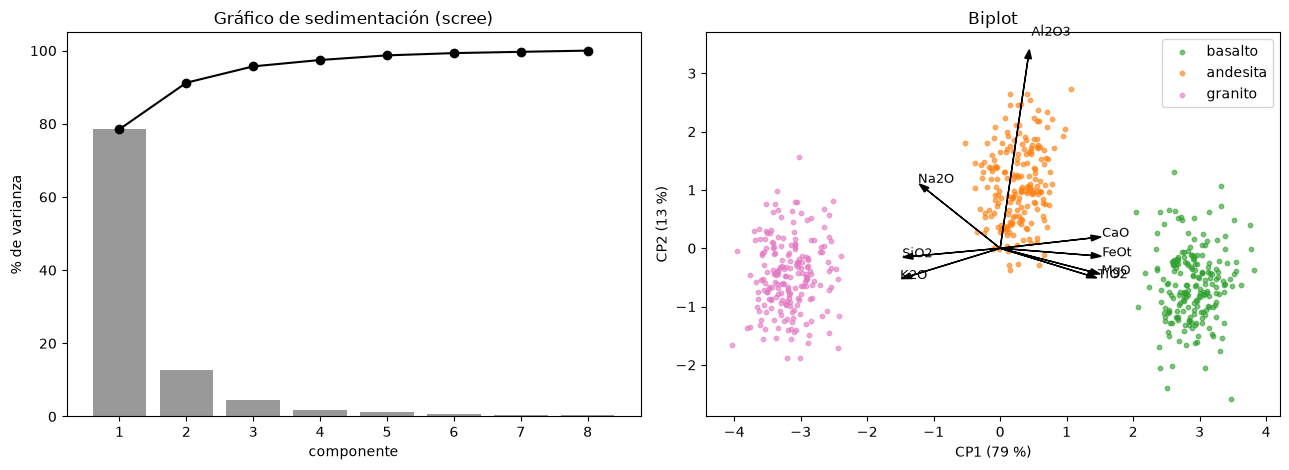

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

oxidos = ['SiO2', 'TiO2', 'Al2O3', 'FeOt', 'MgO', 'CaO', 'Na2O', 'K2O']
medias = {'basalto': [49, 1.8, 15, 11, 8, 10, 2.6, 0.5], 'andesita': [58, 0.9, 17, 7, 4, 7, 3.3, 1.5], 'granito': [72, 0.3, 14, 2.5, 0.8, 1.8, 3.6, 4.2]}
X, lito = [], []
for k, mu in medias.items():
    X.append(rng.normal(mu, np.abs(mu) * 0.06 + 0.15, (200, 8))); lito += [k] * 200
X = np.vstack(X); lito = np.array(lito)
Xs = StandardScaler().fit_transform(X)
pca = PCA().fit(Xs)
Z = pca.transform(Xs)
print('Varianza explicada (%):', np.round(100 * pca.explained_variance_ratio_, 1))
print('Varianza acumulada (%):', np.round(100 * np.cumsum(pca.explained_variance_ratio_), 1))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
axs[0].bar(range(1, 9), 100 * pca.explained_variance_ratio_, color='0.6'); axs[0].plot(range(1, 9), 100 * np.cumsum(pca.explained_variance_ratio_), 'ko-')
axs[0].set_xlabel('componente'); axs[0].set_ylabel('% de varianza'); axs[0].set_title('Gráfico de sedimentación (scree)')
for nom, col in zip(medias, ['tab:green', 'tab:orange', 'tab:pink']):
    m = lito == nom; axs[1].scatter(Z[m, 0], Z[m, 1], s=10, color=col, label=nom, alpha=0.6)
esc = 3.5
for j, ox in enumerate(oxidos):
    axs[1].arrow(0, 0, esc * pca.components_[0, j], esc * pca.components_[1, j], color='k', head_width=0.1)
    axs[1].text(esc * 1.12 * pca.components_[0, j], esc * 1.12 * pca.components_[1, j], ox, fontsize=9)
axs[1].set_xlabel(f'CP1 ({100*pca.explained_variance_ratio_[0]:.0f} %)'); axs[1].set_ylabel(f'CP2 ({100*pca.explained_variance_ratio_[1]:.0f} %)')
axs[1].legend(); axs[1].set_title('Biplot')
plt.tight_layout(); plt.show()

El primer componente concentra casi toda la varianza y opone el SiO2 y el K2O (rocas félsicas) al MgO, el FeOt, el CaO y el TiO2 (rocas máficas): es, en esencia, un índice de diferenciación magmática que el ACP descubrió sin saber nada de petrología. Con dos componentes se separan bien las tres litologías.

El ACP tiene limitaciones. Es lineal, de modo que no capta estructuras curvas. Es sensible a los atípicos y a la escala de las variables. Supone que la varianza es información, lo que no siempre es cierto. Y los componentes, al mezclar todas las variables, pueden ser difíciles de interpretar. Para datos composicionales, como los análisis geoquímicos que suman 100 %, conviene aplicar antes una transformación de razones logarítmicas (por ejemplo, la transformación de razón logarítmica centrada) para evitar correlaciones espurias.

## Análisis discriminante lineal

El ACP no usa ninguna etiqueta: busca varianza. El análisis discriminante lineal (LDA) es su contraparte supervisada: busca las combinaciones de variables que mejor separan clases conocidas, maximizando la razón entre la varianza entre clases y la varianza dentro de las clases. Con $K$ clases produce como máximo $K-1$ ejes discriminantes. Sirve para reducir la dimensionalidad antes de clasificar y como clasificador en sí mismo, suponiendo que las clases tienen distribución normal con la misma matriz de covarianza; si cada clase tiene su propia covarianza, se usa el análisis discriminante cuadrático (QDA). Los diagramas de discriminación tectónica de basaltos, como los de Pearce, son en el fondo análisis discriminantes.

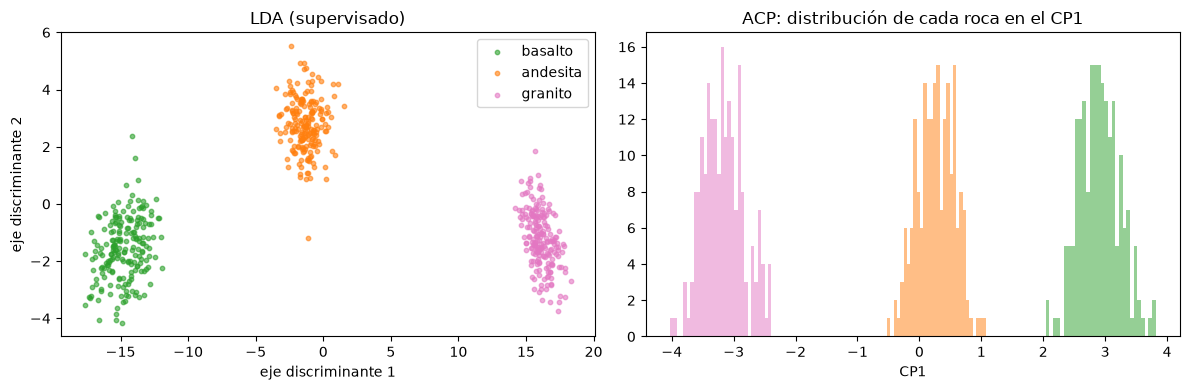

Exactitud del LDA como clasificador (validación cruzada): 1.000


In [3]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score
lda = LinearDiscriminantAnalysis().fit(Xs, lito)
W = lda.transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nom, col in zip(medias, ['tab:green', 'tab:orange', 'tab:pink']):
    m = lito == nom
    ax[0].scatter(W[m, 0], W[m, 1], s=10, color=col, label=nom, alpha=0.6)
ax[0].set_xlabel('eje discriminante 1'); ax[0].set_ylabel('eje discriminante 2'); ax[0].legend(); ax[0].set_title('LDA (supervisado)')
for nom, col in zip(medias, ['tab:green', 'tab:orange', 'tab:pink']):
    m = lito == nom
    ax[1].hist(Z[m, 0], bins=30, alpha=0.5, color=col, label=nom)
ax[1].set_xlabel('CP1'); ax[1].set_title('ACP: distribución de cada roca en el CP1')
plt.tight_layout(); plt.show()
print(f'Exactitud del LDA como clasificador (validación cruzada): {cross_val_score(LinearDiscriminantAnalysis(), Xs, lito, cv=5).mean():.3f}')

## Métodos no lineales

Cuando la estructura de los datos es no lineal se usan otros métodos. t-SNE construye una representación de baja dimensión que conserva las distancias relativas entre vecinos cercanos; es excelente para visualizar grupos, pero no conserva la estructura global ni las distancias entre grupos, y depende de un parámetro poco intuitivo, la perplejidad. UMAP sigue una idea parecida basada en grafos de vecinos, es más rápido y conserva algo mejor la estructura global. Ambos se usan sobre todo para visualizar, no como entrada de otros modelos. Los autocodificadores, redes neuronales que aprenden a comprimir y reconstruir los datos, son la versión no lineal y entrenable del ACP.

## Para profundizar

La sección 12.2 de {cite}`james2021` presenta el ACP y la 4.4, el análisis discriminante. El capítulo 14 de {cite}`hastie2009` trata otros métodos no supervisados. Los notebooks 13 (ACP) y 14 (análisis discriminante) del curso los aplican a datos reales.